# Lending Game — Part 6: Tuning the pricing rule

We are lender 3. This notebook tunes the pricing-rule families of `report/pricing_plan.md` (B0,
R1–R7, plus a no-offer cutoff) so that they maximise our profit **in the simulated market**, i.e.
after the other two lenders' offers and the borrowers' choices, as built in Parts 3 to 5.

**Protocol.**

* Everything here uses the **training set only** (80,000 loans, out-of-fold predictions from
  Part 2). The validation set is kept for Part 7, which scores the tuned rules on scenarios they were
  not tuned on.
* Every simulation uses `simulate_market(mode="expected")`: each borrower's choice is averaged over
  the three preference types, so results have no random noise and rules can be compared exactly.
* Profit is in euros, on loans of EUR 10,000: $+r \cdot 10{,}000$ if the borrower repays,
  $-10{,}000$ if they default.
* Every family also tunes the **rate floor** (the lowest rate we ever offer), over
  0.5%, 1%, 1.5% and 2%.

**Steps** (plan section 3): 3a a quick sensitivity check, 3b the equilibrium margins, 3c the set of
competitor scenarios used for tuning, 3d the grid searches, 3e profit curves, then the Part 6
deliverables.

**Running time.** The full run is roughly 70,000 market simulations, about 15–20 minutes (R5, R6 and
R7 are the largest grids). Two switches below:

* `QUICK_TEST = True` uses tiny grids, to check that the notebook runs end to end in about a
  minute. Its results are meaningless and are saved under separate `_quick` file names.
* `RECOMPUTE = False` reloads grid searches already saved in `data/pricing/` instead of re-running
  them. A saved grid is reused only if it has exactly the parameters and values requested here;
  otherwise that family is re-run automatically.

## 0. Setup

In [1]:
import sys
sys.path.append("..")  # make src/ importable from analysis/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import SEED
from src.pricing_rules import (
    FLOOR_GRID, TUNING_WEIGHTS, load_pricing_data, pts, decile_edges, smooth_bin_margins,
    rule_b0, rule_fixed_margin, rule_markup, rule_adj_p, rule_bins, rule_uncertainty,
    rule_info_advantage, fit_competitor_model, make_undercut_rule,
    best_response_curve, equilibrium_margins, tuning_scenarios,
    undercut_forecasts, grid_search, select_parameters, fit_bin_margins, evaluate,
    save_grid, load_grid, save_tuned, scenario_key)
from src import model_plots as mp
from src import pricing_plots as pp

mp.set_style()
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)

QUICK_TEST = False   # True: tiny grids, only to check that the notebook runs
RECOMPUTE = False    # False: reload grid searches saved in data/pricing/ (True: re-run them, ~10 min)

train = load_pricing_data("train")
print(f"training set: {len(train):,} loans, default rate {train['default'].mean():.2%}")
print("columns:", list(train.columns))

training set: 80,000 loans, default rate 9.95%
columns: ['default', 'p_own', 'p_full', 'p_lender1', 'p_lender2', 'p_public', 'sex_F', 'married', 'employment_retired', 'employment_student', 'employment_unemployed', 'income', 'income_zero', 'signal3', 'signal3_missing']


The training set has the 80,000 loans of Part 1's split with their out-of-fold Part 2 predictions
(default rate 9.95%). Only our own features are loaded next to the predictions; `signal1` and
`signal2` are not, so no rule can use the competitors' information by accident.

**Grids.** One place for every grid of the plan, in decimals (0.0025 = 0.25 point). With
`QUICK_TEST`, each grid shrinks to two or three values.

In [2]:
if not QUICK_TEST:
    FLOORS = FLOOR_GRID                         # 0.5%, 1%, 1.5%, 2%
    MARGINS = pts(0, 0.08, 0.0025)              # R1, 3b: 0 to 8 pts, step 0.25
    BR_MARGINS = pts(0, 0.15, 0.0025)           # 3a: 0 to 15 pts (best response can price out)
    GRIDS = {
        "B0": {"floor": FLOORS},
        "R1": {"m": MARGINS, "floor": FLOORS},
        "R2": {"k": pts(0, 1, 0.05), "floor": FLOORS},
        "R3": {"a": pts(0, 0.6, 0.05), "m": [0.0, 0.01, 0.02], "floor": FLOORS},
        "R5": {"m0": pts(0, 0.04, 0.005), "m1": pts(0, 0.04, 0.005), "m2": pts(0, 0.08, 0.005),
               "floor": FLOORS},
        "R6": {"m0": pts(0, 0.08, 0.0025), "m1": pts(-1, 1, 0.1), "floor": FLOORS},
        "R7": {"delta": pts(-0.08, 0.03, 0.0025), "q": [0.25, 0.5], "a": pts(0, 1.0, 0.2),
               "floor": FLOORS},
    }
    BIN_MARGINS = pts(-0.02, 0.20, 0.0025)      # R4: -2 to +20 pts per decile
    CUTOFFS = [0.1, 0.125, 0.15, 0.175, 0.2, 0.25, 0.3, 0.4, 0.5]   # +C
    TAG = ""
else:
    FLOORS = [0.01]
    MARGINS = [0.0, 0.02, 0.04]
    BR_MARGINS = MARGINS
    GRIDS = {
        "B0": {"floor": FLOORS},
        "R1": {"m": MARGINS, "floor": FLOORS},
        "R2": {"k": [0.0, 0.2], "floor": FLOORS},
        "R3": {"a": [0.0, 0.3], "m": [0.0, 0.01], "floor": FLOORS},
        "R5": {"m0": [0.0, 0.02], "m1": [0.0, 0.02], "m2": [0.0], "floor": FLOORS},
        "R6": {"m0": [0.0, 0.02], "m1": [-0.5, 0.5], "floor": FLOORS},
        "R7": {"delta": [-0.02, 0.0], "q": [0.5], "a": [0.0, 0.2], "floor": FLOORS},
    }
    BIN_MARGINS = [0.0, 0.02, 0.04]
    CUTOFFS = [0.3, 0.5]
    TAG = "_quick"

for family, grid in GRIDS.items():
    print(f"{family}: {int(np.prod([len(v) for v in grid.values()])):>5} combinations x 6 scenarios")

B0:     4 combinations x 6 scenarios
R1:   132 combinations x 6 scenarios
R2:    84 combinations x 6 scenarios
R3:   156 combinations x 6 scenarios
R5:  5508 combinations x 6 scenarios
R6:  2772 combinations x 6 scenarios
R7:  2160 combinations x 6 scenarios


About 10,800 parameter combinations, each simulated against the six scenarios. R5 (5,508), R6 (2,772)
and R7 (2,160) are by far the largest grids. With `RECOMPUTE = False`, a saved grid is reloaded only
if it was computed against the same six scenarios (fingerprint of their rates) and has exactly the
parameters and values above. 3a, 3b, R4, the cutoff step and section 4 are recomputed at every run;
they are deterministic.

## 1. The rule families

All rules start from the break-even rate $be(p) = p/(1-p)$ of Part 3, applied to our predicted
default probability $p$ (`p_own`). Shared rules: no offer when $p \ge 0.5$, **no offer when the rate
would be above 100%**, and rates below the floor are raised to the floor.

| ID | Rule | Formula | Tuned parameters |
|---|---|---|---|
| **B0** | Naive baseline | $r = be(p)$ | floor |
| **R1** | Fixed margin | $r = be(p) + m$ | $m$, floor |
| **R2** | Proportional markup | $r = (1+k)\,be(p)$ | $k$, floor |
| **R3** | Adjusted p | $\text{logit}(p_{adj}) = \text{logit}(p) + a$, $r = be(p_{adj}) + m$ | $a$, $m$, floor |
| **R4** | Margin per risk decile | $r = be(p) + m(p)$, $m(p)$ an increasing curve through the best margin of each decile | one margin per decile, floor |
| **R5** | Margin growing with uncertainty | $r = be(p) + m_0 + m_1 \mathbb 1[\text{signal3 missing}] + m_2 \mathbb 1[\text{income}=0]$ | $m_0, m_1, m_2$, floor |
| **R6** | Information advantage | $r = be(p) + m_0 + m_1 (p_{pub} - p)$ | $m_0, m_1$, floor |
| **R7** | Undercut the predicted competitor | $r = \max(be(p_{adj}),\ \hat r_{comp} - \delta)$, $\hat r_{comp}$ forecast assuming competitors charge break-even + $\hat m$ | $\delta$, $q$, $a$, $\hat m$, floor |
| **+C** | No-offer cutoff | no offer if $p \ge \bar p$ | $\bar p$ (on the best 1–2 rules) |

No rule uses the competitors' predictions or signals: only `p_own`, `p_public` and our own
features. The competitors' predictions are used only to **simulate** their offers.

## 3a. Sensitivity check: how much does our best margin depend on the competitors?

For R1 (break-even + a fixed margin $m$) we find the margin, from 0 to 15 points, that maximises our
profit against competitors who price at break-even + 0, 1, 2, 3 or 5 points. The floor is held at 1%.
The range goes beyond R1's own grid (0–8 points) because against aggressive competitors the best
response can be to price ourselves out of the market.

**How to read it.** If the best-response curve is flat, our best margin hardly depends on what the
competitors do, and the choice of tuning scenarios matters little. If it moves a lot, tuning against
several scenarios (3c) is essential.

,best_margin,best_profit,loans_won
comp_margin,,,
0%,15.00%,"-391,970",266
1%,15.00%,"-426,418",334
2%,3.50%,"+233,534","18,006"
3%,4.25%,"+1,959,917","19,646"
5%,2.75%,"+7,911,024","50,923"


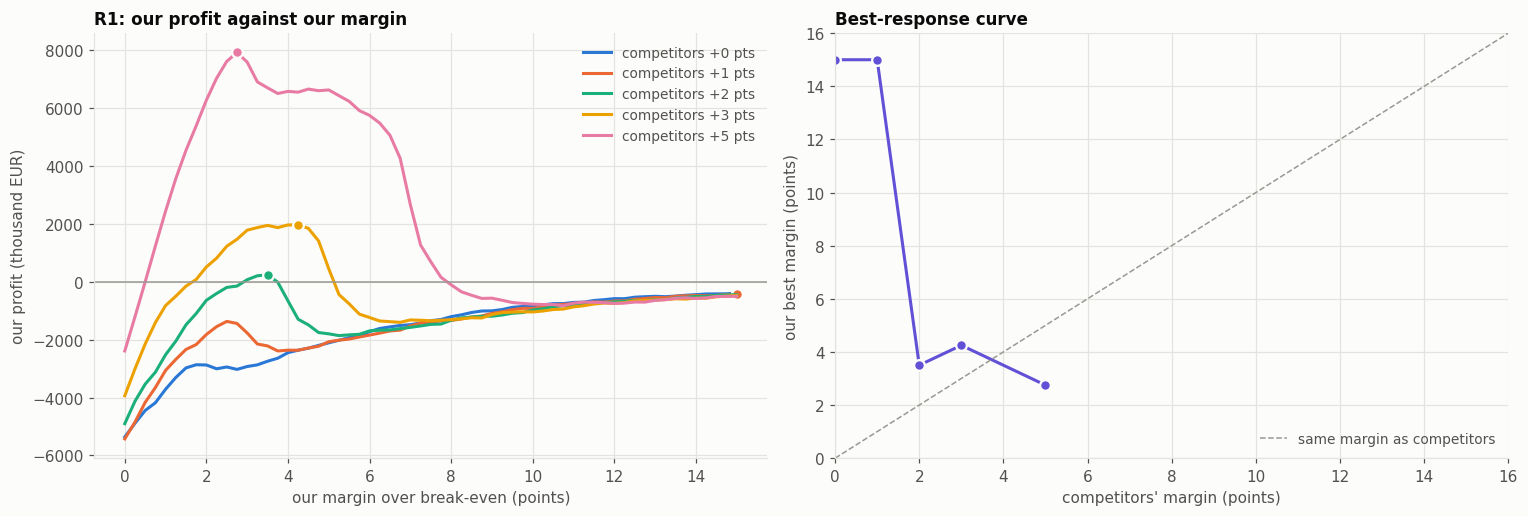

In [3]:
br_table, br_curves = best_response_curve(train, our_margins=BR_MARGINS, floor=0.01)
display(br_table.style.format({"best_margin": "{:.2%}", "best_profit": "{:+,.0f}",
                               "loans_won": "{:,.0f}"}).format_index("{:.0%}"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
pp.plot_best_response(br_table, br_curves, axes)
fig.tight_layout()
plt.show()

**Findings.**

| competitors' margin | our best margin | our profit | loans we win |
|---|---|---|---|
| 0 (break-even) | 15 pts (edge of the grid) | −€0.39M | 266 |
| +1 pt | 15 pts (edge of the grid) | −€0.43M | 334 |
| +2 pts | 3.5 pts | +€0.23M | 18,006 |
| +3 pts | 4.25 pts | +€1.96M | 19,646 |
| +5 pts | 2.75 pts | +€7.91M | 50,923 |

* **Against aggressive competitors (0 or +1 point), no margin makes money.** Profit keeps rising
  towards zero as our margin grows, and the "best" response, 15 points, is a way of lending to almost
  nobody (fewer than 340 loans). The edge of the grid does not matter here: the real best response is
  to stay out of the market.
* **Against expensive competitors, undercutting pays.** At +5 points our best margin is 2.75 points,
  about 2 points below theirs, and we win 64% of the applicants (+€7.9M). At +2 and +3 points we price
  slightly *above* them (3.5 and 4.25 points) and rely on the borrowers who prefer us.
* **Our profit swings from −€0.4M to +€7.9M with the competitors' margin alone.** The best response
  is far from flat, so tuning against a set of scenarios (3c) is essential.

## 3b. Equilibrium scenario

Competitors will not price at break-even (Part 3 showed it loses money). We look for the margins
the three lenders end up with when each one, in turn, picks the margin (0 to 8 points) that
maximises its own profit given the other two, starting from break-even + 2 points for everyone,
until no margin moves by more than 0.25 point (at most 20 rounds). Each lender uses its own default
probabilities (`p_lender1`, `p_lender2`, `p_own`) and the competitor pricing rules of Part 3.

**If the margins converge**, the competitors' final margins $(m_1^{eq}, m_2^{eq})$ define T6.
**If they cycle instead** (each lender undercuts the others until margins are so low that pricing
high again pays), the last round is an arbitrary point of the cycle. T6 then uses the **average
margins over the cycle** (rounds 3 to 20; rounds 1–2 are a warm-up from the starting point),
rounded to the 0.25-point grid: the typical level the competitors charge over time.

converged: False after 20 round(s)
last round        : lender 1 4.50%, lender 2 4.50%, us 2.25%
average after warm-up: lender 1 4.32%, lender 2 3.82%, us 3.35%
T6 uses           : lender 1 4.25%, lender 2 3.75%


,m1,m2,m3
round,,,
0,2.00%,2.00%,2.00%
1,3.00%,3.25%,3.75%
2,4.25%,4.50%,4.25%
3,5.00%,2.75%,2.50%
4,3.75%,3.75%,3.75%
5,4.50%,4.50%,2.25%
6,3.50%,3.50%,4.00%
7,4.50%,4.25%,4.50%
8,5.25%,3.00%,2.75%


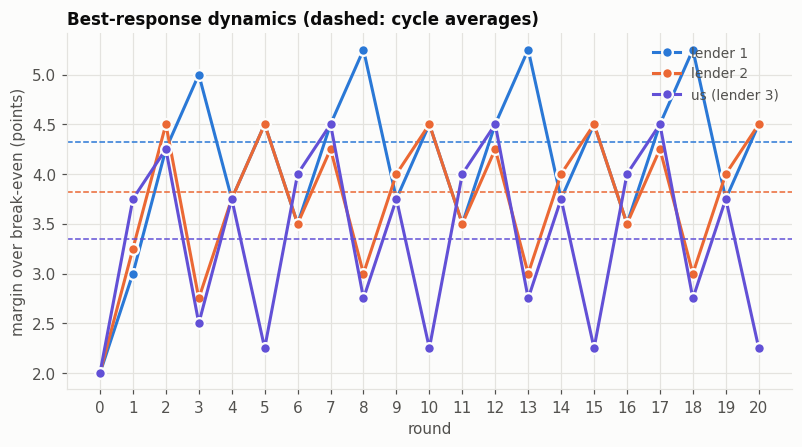

In [4]:
eq = equilibrium_margins(train, grid=MARGINS, start=0.02, tol=0.0025, max_rounds=20, burn_in=2)
EQ_MARGINS = eq["scenario_margins"][:2]   # lenders 1 and 2 -> scenario T6

print(f"converged: {eq['converged']} after {eq['rounds']} round(s)")
print(f"last round        : lender 1 {eq['margins'][0]:.2%}, lender 2 {eq['margins'][1]:.2%}, "
      f"us {eq['margins'][2]:.2%}")
print(f"average after warm-up: lender 1 {eq['cycle_mean'][0]:.2%}, lender 2 {eq['cycle_mean'][1]:.2%}, "
      f"us {eq['cycle_mean'][2]:.2%}")
print(f"T6 uses           : lender 1 {EQ_MARGINS[0]:.2%}, lender 2 {EQ_MARGINS[1]:.2%}")
display(eq["history"].style.format("{:.2%}"))

fig, ax = plt.subplots(figsize=(8.5, 4.2))
pp.plot_equilibrium_path(eq["history"], ax, cycle_mean=None if eq["converged"] else eq["cycle_mean"])
plt.show()

**Findings.**

* **The margins never converge: they cycle.** From round 4 the same five-round cycle repeats
  exactly: (3.75, 3.75, 3.75) → (4.5, 4.5, 2.25) → (3.5, 3.5, 4.0) → (4.5, 4.25, 4.5) →
  (5.25, 3.0, 2.75) points for (lender 1, lender 2, us). This is an **Edgeworth cycle**: each
  lender undercuts the others while that pays, until margins are low enough (3a: around 0–1 point)
  that the best response is to jump back up.
* There is no stable set of margins, so T6 uses the **average over the cycle** (rounds 3–20):
  lender 1 4.32%, lender 2 3.82%, us 3.35%, rounded to **4.25% and 3.75%** for the competitors. This
  is what competitors who keep best-responding charge on average. It sits between T2 (+2) and
  T3 (+4).
* Lender 1 tends to charge more than lender 2, and we charge least on average (3.35 points). In this
  market, best-responding lenders end up at **about 3–4.5 points over break-even**.

## 3c. Tuning set

Six competitor scenarios. Margins and markups are on top of each competitor's own break-even rate:

| Scenario | Competitor rates | Weight | Why |
|---|---|---|---|
| T1–T3 | $be(p_k) + m$, $m \in \{0, 2, 4\}$ points | 1/7 each | low, central, high margin |
| T4–T5 | $(1+k)\,be(p_k)$, $k \in \{0.15, 0.35\}$ | 1/7 each | the other shape: cheap on safe borrowers, expensive on risky ones |
| T6 | margins from 3b (average over the best-response cycle) | 2/7 | the most plausible case: what competitors who keep best-responding charge on average |

All other scenarios (asymmetric margins, other markups, competitors using our rule, competitors
knowing more or less) are kept for Part 7, so that Part 7 tests the rules on scenarios they were not
tuned on.

In [5]:
scenarios = tuning_scenarios(train, EQ_MARGINS)
weights = TUNING_WEIGHTS

summary = pd.DataFrame({
    name: {"weight": weights[name],
           "lender 1 median rate": r1.median(), "lender 2 median rate": r2.median(),
           "lender 1 no offer": int(r1.isna().sum()), "lender 2 no offer": int(r2.isna().sum())}
    for name, (r1, r2) in scenarios.items()}).T
display(summary.style.format({"weight": "{:.3f}", "lender 1 median rate": "{:.2%}",
                              "lender 2 median rate": "{:.2%}",
                              "lender 1 no offer": "{:,.0f}", "lender 2 no offer": "{:,.0f}"}))

,weight,lender 1 median rate,lender 2 median rate,lender 1 no offer,lender 2 no offer
T1,0.143,9.49%,9.53%,0,0
T2,0.143,11.49%,11.53%,0,0
T3,0.143,13.49%,13.53%,0,0
T4,0.143,10.92%,10.96%,6,0
T5,0.143,12.80%,12.86%,73,28
T6,0.286,13.74%,13.28%,0,0


T1–T5 are as designed, and T6 has competitor median rates of 13.7% (lender 1) and 13.3% (lender 2),
between T2 and T3. The markups produce a few "no offers" (T5: 73 and 28 applicants whose rate would
exceed 100%). The tuning set spans competitor median rates from 9.5% to 13.7%.

## 3d. Grid search

For each family and each parameter combination, our profit is simulated against each of T1–T6.
Two summaries per combination:

* **Weighted profit** $= \sum_s w_s\,\Pi_s$, with the weights of 3c.
* **Max regret** $= \max_s\,[\max_\theta \Pi_s(\theta) - \Pi_s]$: in the worst scenario, how much
  less we earn than the best parameters *of the same family* would have earned in that scenario.

**Selection rule** (plan 3d): the highest weighted profit. We also look at the smallest max regret;
if both pick the same parameters we keep them, otherwise we keep the one with the **higher margin**
(higher average rate offered), because a margin that is too low loses money on the loans we win
while one that is too high only loses volume.

Each grid is saved to `data/pricing/grid_<family>.csv`.

In [6]:
RULES = {"B0": rule_b0, "R1": rule_fixed_margin, "R2": rule_markup, "R3": rule_adj_p,
         "R5": rule_uncertainty, "R6": rule_info_advantage}
RESULTS, SELECTED, TUNED = {}, {}, {}
SCENARIO_KEY = scenario_key(scenarios)   # fingerprint of T1-T6, saved with each grid


def grid_matches(results, grid):
    # A saved grid is reused only if it was computed against the same scenarios (T6 can
    # change) and has exactly these parameters and values.
    if "scenario_key" not in results.columns or results["scenario_key"].iloc[0] != SCENARIO_KEY:
        return False
    if set(grid) != {c for c in results.columns
                     if not c.startswith(("profit_", "loans_")) and c not in
                     ("mean_rate", "offer_share", "weighted", "max_regret", "scenario_key")}:
        return False
    return all(set(np.round(results[p].astype(float), 6)) == set(np.round(np.asarray(v, float), 6))
               for p, v in grid.items())


def run_family(family, rule, grid, fixed=None):
    # Grid search of one family (or reload it), then the selection rule.
    results = None if RECOMPUTE else load_grid(family + TAG)
    if results is not None and not grid_matches(results, grid):
        print(f"{family}: no saved grid for these scenarios and parameters, running it")
        results = None
    if results is None:
        print(f"{family}: grid search")
        results = grid_search(rule, grid, scenarios, weights, train, fixed=fixed)
        results["scenario_key"] = SCENARIO_KEY
        save_grid(results, family + TAG)
    selection = select_parameters(results, list(grid))
    RESULTS[family], SELECTED[family], TUNED[family] = results, selection, selection["chosen"]
    agree = "both criteria agree" if selection["agree"] else "criteria disagree: higher margin kept"
    print(f"{family}: chosen {selection['chosen']} ({agree})")
    params_fmt = {c: "{:.4g}" for c in grid}
    display(selection["table"].style.format({**params_fmt, "weighted": "{:+,.0f}",
                                              "max_regret": "{:,.0f}", "mean_rate": "{:.2%}",
                                              "offer_share": "{:.1%}"}))
    return results

### B0 — naive baseline

Only the floor varies. B0 is the reference every other rule has to beat.

In [7]:
run_family("B0", rule_b0, GRIDS["B0"]);

B0: chosen {'floor': 0.02} (both criteria agree)


,floor,weighted,max_regret,mean_rate,offer_share
best weighted profit,0.02,"-3,402,836",0,12.13%,100.0%
smallest max regret,0.02,"-3,402,836",0,12.13%,100.0%
chosen,0.02,"-3,402,836",0,12.13%,100.0%


**B0 loses money in every scenario**: from −€2.13M (T6) to −€5.04M (T1), weighted **−€3.40M**.
Pricing at break-even only works if nothing selects which borrowers we win; under competition it is
the benchmark to beat, not a strategy. The floor helps a little (2% is best) because it adds a margin
on the safest borrowers, whose break-even rate is close to 0.

### R1 — fixed margin, and R2 — proportional markup

The two one-parameter families: an additive margin (the same number of points for everyone) and a
proportional markup (more points on riskier borrowers).

In [8]:
run_family("R1", rule_fixed_margin, GRIDS["R1"])
run_family("R2", rule_markup, GRIDS["R2"]);

R1: chosen {'m': 0.04, 'floor': 0.005} (criteria disagree: higher margin kept)


,m,floor,weighted,max_regret,mean_rate,offer_share
best weighted profit,0.0375,0.005,"+1,216,930","1,434,109",15.72%,100.0%
smallest max regret,0.04,0.005,"+1,184,443","1,242,971",15.97%,100.0%
chosen,0.04,0.005,"+1,184,443","1,242,971",15.97%,100.0%


R2: chosen {'k': 0.7, 'floor': 0.02} (criteria disagree: higher margin kept)


,k,floor,weighted,max_regret,mean_rate,offer_share
best weighted profit,0.7,0.02,"+1,988,901","648,012",20.00%,99.5%
smallest max regret,0.55,0.02,"+1,910,457","434,493",18.37%,99.7%
chosen,0.7,0.02,"+1,988,901","648,012",20.00%,99.5%


* **R1, fixed margin: 4 points, weighted +€1.18M.** The highest weighted profit is at 3.75 points
  (+€1.22M); minimax regret picks 4 points and the plan's rule keeps the higher margin. The floor
  plays no role: a 4-point margin puts every rate above 2%.
* **R2, proportional markup: $r = 1.7 \times be(p)$ ($k = 0.70$), weighted +€1.99M**, €0.8M more than
  R1. Minimax regret prefers $k = 0.55$ (+€1.91M); the plan's rule keeps the higher margin. The weighted
  curve is flat between 0.55 and 0.85 (3e). The 2% floor is the best floor.
* **Lesson: the margin has to grow with risk.** A proportional markup charges safe borrowers less and
  risky borrowers more than a flat margin, and that is worth €0.8M. This matches Part 5, where the
  winner's curse grows with risk.

### R3 — adjusted p

Our probability is shifted up on the log-odds scale before pricing, $\text{logit}(p_{adj}) =
\text{logit}(p) + a$, which corrects for the winner's curse more strongly on risky borrowers, plus a
small margin $m$.

In [9]:
run_family("R3", rule_adj_p, GRIDS["R3"]);

R3: chosen {'a': 0.35, 'm': 0.01, 'floor': 0.02} (both criteria agree)


,a,m,floor,weighted,max_regret,mean_rate,offer_share
best weighted profit,0.35,0.01,0.02,"+2,051,672","528,924",17.84%,99.8%
smallest max regret,0.35,0.01,0.02,"+2,051,672","528,924",17.84%,99.8%
chosen,0.35,0.01,0.02,"+2,051,672","528,924",17.84%,99.8%


**R3: $a = 0.35$, $m = 1$ point, floor 2%: weighted +€2.05M**, and both criteria agree. Shifting the
log-odds by 0.35 multiplies the odds of default by $e^{0.35} \approx 1.42$ before pricing, which adds
a margin that grows faster than linearly with risk. It beats R2 (+€0.06M) and R1 (+€0.87M). The
optimum is flat between $a = 0.25$ and $0.5$ (3e).

### R4 — margin per risk decile

The training set is cut into deciles of `p_own`. For each decile and each floor, we find the margin
(−2 to +20 points) with the highest weighted profit over T1–T6. This can be done decile by decile
because a borrower's choice depends only on the three rates offered to them, so one decile's
margin does not affect another's profit.

Ten free margins over-fit easily, so they are **smoothed into an increasing curve** $m(p)$ by
isotonic regression, and the smoothed rule is what we keep. The floor is chosen on the weighted
profit of the smoothed rule.

,floor,weighted (smoothed),weighted (raw decile margins),profit_T1,profit_T2,profit_T3,profit_T4,profit_T5,profit_T6
0,0.5%,"+2,706,980","+2,987,843","+143,644","+1,597,364","+4,901,661","+665,266","+1,973,492","+4,833,716"
1,1.0%,"+2,706,980","+2,987,843","+143,644","+1,597,364","+4,901,661","+665,266","+1,973,492","+4,833,716"
2,1.5%,"+2,706,980","+2,987,843","+143,644","+1,597,364","+4,901,661","+665,266","+1,973,492","+4,833,716"
3,2.0%,"+2,706,320","+2,987,183","+152,770","+1,606,490","+4,929,040","+674,392","+1,982,618","+4,799,465"


R4: chosen floor 0.5%


,n,p_low,p_high,centre,best_margin,best_profit,smoothed_margin
bin,,,,,,,
0,8000,0.01%,1.22%,0.53%,1.75%,"+695,205",1.75%
1,8000,1.22%,2.75%,1.97%,1.75%,"+637,905",1.75%
2,8000,2.75%,4.47%,3.58%,2.00%,"+765,201",2.00%
3,8000,4.47%,6.45%,5.42%,3.50%,"+413,133",3.17%
4,8000,6.45%,8.69%,7.53%,3.00%,"+353,278",3.17%
5,8000,8.69%,11.10%,9.86%,3.00%,"+347,149",3.17%
6,8000,11.10%,13.28%,12.32%,20.00%,"-51,290",16.88%
7,8000,13.28%,15.42%,14.09%,13.75%,"-44,581",16.88%
8,7994,15.42%,20.55%,17.74%,19.75%,"+24,512",19.38%


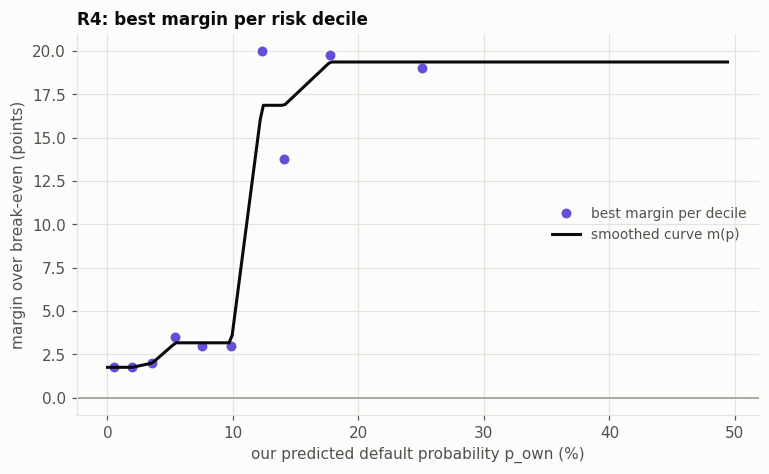

In [10]:
edges = decile_edges(train["p_own"])
r4_rows, r4_fits = [], {}
for floor in FLOORS:
    table, profit = fit_bin_margins(train, scenarios, weights, edges, BIN_MARGINS, floor=floor)
    curve = smooth_bin_margins(table["centre"], table["best_margin"], method="isotonic")
    score = grid_search(rule_bins, {"floor": [floor]}, scenarios, weights, train,
                        fixed={"edges": edges, "margin_curve": curve}, progress=False)
    step = grid_search(rule_bins, {"floor": [floor]}, scenarios, weights, train,
                       fixed={"edges": edges, "margins": table["best_margin"].to_numpy()},
                       progress=False)
    r4_fits[floor] = {"table": table, "curve": curve, "profit": profit}
    r4_rows.append({"floor": floor, "weighted (smoothed)": score["weighted"].iloc[0],
                    "weighted (raw decile margins)": step["weighted"].iloc[0],
                    **{f"profit_{s}": score[f"profit_{s}"].iloc[0] for s in scenarios}})

r4_results = pd.DataFrame(r4_rows)
save_grid(r4_results, "R4" + TAG)
display(r4_results.style.format({c: ("{:.1%}" if c == "floor" else "{:+,.0f}") for c in r4_results.columns}))

R4_FLOOR = float(r4_results.loc[r4_results["weighted (smoothed)"].idxmax(), "floor"])
r4_best = r4_fits[R4_FLOOR]
r4_centres = r4_best["table"]["centre"].to_numpy()
r4_margins = r4_best["curve"](r4_centres)          # smoothed margin at each decile centre
TUNED["R4"] = {"floor": R4_FLOOR, "edges": edges, "centres": r4_centres, "margins": r4_margins}
print(f"R4: chosen floor {R4_FLOOR:.1%}")
display(r4_best["table"].assign(smoothed_margin=r4_margins)
        .style.format({"p_low": "{:.2%}", "p_high": "{:.2%}", "centre": "{:.2%}",
                       "best_margin": "{:.2%}", "smoothed_margin": "{:.2%}",
                       "best_profit": "{:+,.0f}"}))

fig, ax = plt.subplots(figsize=(8, 4.5))
pp.plot_bin_margins(r4_best["table"], r4_best["curve"], ax)
plt.show()

**Findings.**

* **The best margin rises with risk, in three steps:**
  * 1.75–2 points in the three safest deciles ($p_{own}$ below 4.5%);
  * 3–3.5 points (3.2 smoothed) in the middle deciles (4.5% to 11%);
  * then a jump to **14–20 points** above 11%.
* **Above about 11%, the margin really means "don't lend".** The four riskiest deciles make about zero
  at their best margin (−€153k to +€25k), with 14–20 points of margin. Rates that high win almost
  nobody, so the edge of the grid (20 points) does not matter: lending to these borrowers simply does
  not pay. The cutoff (+C) makes this explicit.
* The floor is irrelevant (0.5%, 1% and 1.5% are identical; 2% costs €1k). We keep 0.5%.
* **Smoothing costs €281k** (raw decile margins +€2.99M, smoothed curve +€2.71M). The raw margins zig-zag
  (3.5, 3, 3; then 20, 13.75, 19.75, 19), and we keep the smooth increasing curve because a margin that
  falls when risk rises is more likely noise than a real effect. Even smoothed, **R4 is the best family
  before the cutoff**.

### R5 — margin growing with uncertainty

Extra points when our signal is missing ($m_1$) or the applicant has no income ($m_2$). This is the
largest grid (9 × 9 × 17 values × 4 floors; $m_2$ goes up to 8 points). The plan also suggests testing a **low** `signal3`
rather than a missing one: `rule_uncertainty` has an optional term $m_3\,\mathbb 1[0 <
\text{signal3} < 0.2]$; add `"m3": [...]` to `GRIDS["R5"]` to include it.

In [11]:
run_family("R5", rule_uncertainty, GRIDS["R5"]);

R5: chosen {'m0': 0.035, 'm1': 0.02, 'm2': 0.08, 'floor': 0.005} (criteria disagree: higher margin kept)


,m0,m1,m2,floor,weighted,max_regret,mean_rate,offer_share
best weighted profit,0.035,0.02,0.08,0.005,"+1,825,763","779,361",17.25%,100.0%
smallest max regret,0.025,0.025,0.08,0.005,"+1,719,063","445,766",16.35%,100.0%
chosen,0.035,0.02,0.08,0.005,"+1,825,763","779,361",17.25%,100.0%


**R5: $m_0 = 3.5$ points, $m_1 = +2$ points when `signal3` is missing, $m_2 = +8$ points when income is
0, floor 0.5%: weighted +€1.83M** (the highest weighted profit; minimax regret prefers $m_0 = 2.5$,
$m_1 = 2.5$, +€1.72M, and the plan's rule keeps the higher margin).

* **The zero-income premium goes to the top of its grid (8 points)**, and profit still rises slowly
  there (3e). An extra 8 points mostly prices zero-income applicants out of the market, like R4 does
  for the riskiest deciles.
* **The missing-signal premium is modest**: profit is flat up to $m_1 = 2$ points and falls beyond.
* R5 is still below R2–R4. A flat base margin plus two flags does not capture how the winner's curse
  grows with risk.

### R6 — information advantage

$r = be(p) + m_0 + m_1 (p_{pub} - p)$, where $p_{pub}$ is the public-only model of Part 2. Where our
signal makes us more optimistic than the public data ($p < p_{pub}$), the competitors, who do not see
our signal, are likely to price higher than us. $m_1 > 0$ uses that room to charge more; $m_1 < 0$
would mean the opposite. The grid lets the data decide.

In [12]:
run_family("R6", rule_info_advantage, GRIDS["R6"]);

R6: chosen {'m0': 0.0475, 'm1': -0.7, 'floor': 0.005} (criteria disagree: higher margin kept)

,m0,m1,floor,weighted,max_regret,mean_rate,offer_share
best weighted profit,0.0375,-0.2,0.005,"+1,237,306","1,616,992",15.71%,100.0%
smallest max regret,0.0475,-0.7,0.005,"+1,039,777","1,317,148",16.68%,100.0%
chosen,0.0475,-0.7,0.005,"+1,039,777","1,317,148",16.68%,100.0%


**R6: $m_0 = 4.75$ points, $m_1 = -0.7$: weighted +€1.04M.** The best weighted choice was
$m_0 = 3.75$, $m_1 = -0.2$ (+€1.24M). Minimax regret picked the higher margin, which here costs €0.2M.

* **The information-advantage term does not help.** R6 is no better than R1 (+€1.18M), and its slope
  is negative, the opposite of the plan's intuition. With $m_1 < 0$ we charge *less* where our signal
  says the borrower is safer than the public data ($p_{pub} > p_{own}$), and more where it says riskier.
* The base margin peaks around 5 points; above that, profit falls quickly (3e).

### R7 — undercut the predicted competitor rate

1. On the training set, regress the competitors' default probabilities (log-odds) on **our own**
   information (`p_own`, `p_public`, our features). The competitors' predictions are only the
   target, never an input.
2. Turn 50 draws of the predicted probabilities (prediction + resampled residuals) into the
   competitors' **break-even** rates, and take the $q$-quantile of the cheaper of the two:
   $\hat r_{comp}$.
3. Offer $\max(be(p_{adj}),\ \hat r_{comp} - \delta)$, but never below our (adjusted) break-even.
   $\delta < 0$ prices **above** the competitors' predicted break-even: $\delta = -2$ points means
   "2 points above it".

**No information about the scenario is used.** The competitors' real pricing is unknown, and R7 never
sees the scenario it is scored in. (A first version forecast with each scenario's true pricing,
which leaks information we will not have for the new applicants.) An assumed competitor margin
$\hat m$ is not a separate parameter: assuming they charge break-even + $\hat m$ shifts
$\hat r_{comp}$ by $\hat m$, exactly like changing $\delta$ by $-\hat m$. The two were redundant, so
$\delta$ carries it, over a wide range (−8 to +3 points). For the new applicants (Part 8), R7 needs
`p_public` to be computed.

In [13]:
competitor_model = fit_competitor_model(train)
# One forecast per quantile, shared by all six scenarios (competitors' break-even rates only).
forecasts = undercut_forecasts(competitor_model, train, qs=sorted(set(GRIDS["R7"]["q"])),
                               n_draws=50, seed=SEED)
rule_r7 = make_undercut_rule(forecasts)
RULES["R7"] = rule_r7
run_family("R7", rule_r7, GRIDS["R7"]);

R7: chosen {'delta': -0.02, 'q': 0.5, 'a': 0.4, 'floor': 0.005} (criteria disagree: higher margin kept)


,delta,q,a,floor,weighted,max_regret,mean_rate,offer_share
best weighted profit,-0.0175,0.5,0.4,0.005,"+2,229,060","1,213,007",17.85%,99.8%
smallest max regret,-0.02,0.5,0.4,0.005,"+2,163,506","1,069,438",17.91%,99.8%
chosen,-0.02,0.5,0.4,0.005,"+2,163,506","1,069,438",17.91%,99.8%


**R7: $\delta = -2$ points, $q = 0.5$, $a = 0.4$, floor 0.5%: weighted +€2.16M** (best weighted
$\delta = -1.75$, +€2.23M; minimax regret and the plan's rule keep −2).

* **R7 prices 2 points above the competitors' predicted break-even rate** (median forecast of the
  cheaper of the two), with our own break-even shifted by $a = 0.4$ as a floor. All parameters are now
  inside their grids.
* **Removing the leak costs R7 €0.65M.** The first version, which knew each scenario's competitor
  pricing, scored +€2.81M; the fair version, which never sees the scenario, scores +€2.16M. It drops
  from first to second place behind R4 (+€2.71M).
* **The profit curve in $\delta$ is bumpy** (3e): a main peak at −1.75 to −2 points, and a second one
  around −5 points in T3 and T6, where the competitors charge more.

### +C — no-offer cutoff on the best two families

The two families with the highest weighted profit are re-run with their tuned parameters fixed and
a cutoff $\bar p$: no offer when $p \ge \bar p$. A cutoff of 0.5 is the plain rule.

In [14]:
FIXED = {"R4": {"edges": edges, "margin_curve": smooth_bin_margins(r4_centres, r4_margins)}}
RULES["R4"] = rule_bins


def tuned_kwargs(family):
    # The parameters to call a tuned rule with (R4 is rebuilt from its smoothed curve).
    if family == "R4":
        return {"floor": TUNED["R4"]["floor"], **FIXED["R4"]}
    return dict(TUNED[family])


family_scores = pd.Series({f: grid_search(RULES[f], {"floor": [tuned_kwargs(f).pop("floor")]},
                                          scenarios, weights, train,
                                          fixed={k: v for k, v in tuned_kwargs(f).items() if k != "floor"},
                                          progress=False)["weighted"].iloc[0]
                           for f in TUNED})
best_two = family_scores.drop("B0").nlargest(2).index.tolist()
print("weighted profit of each tuned family:")
display(family_scores.sort_values(ascending=False).to_frame("weighted").style.format("{:+,.0f}"))
print("cutoff tried on:", best_two)

for family in best_two:
    kwargs = tuned_kwargs(family)
    results = grid_search(RULES[family], {"cutoff": CUTOFFS}, scenarios, weights, train,
                          fixed=kwargs, progress=False)
    save_grid(results, f"{family}C{TAG}")
    best = results.loc[results["weighted"].idxmax()]
    RESULTS[f"{family}+C"] = results
    TUNED[f"{family}+C"] = {**({k: v for k, v in TUNED[family].items()}), "cutoff": best["cutoff"]}
    print(f"{family}+C: best cutoff {best['cutoff']:.2f}, weighted {best['weighted']:+,.0f} "
          f"(without cutoff {family_scores[family]:+,.0f})")
    display(results[["cutoff", "weighted", "max_regret", "offer_share"]]
            .style.format({"cutoff": "{:.2f}", "weighted": "{:+,.0f}", "max_regret": "{:,.0f}",
                           "offer_share": "{:.1%}"}))

weighted profit of each tuned family:


,weighted
R4,"+2,706,980"
R7,"+2,163,506"
R3,"+2,051,672"
R2,"+1,988,901"
R5,"+1,825,763"
R1,"+1,184,443"
R6,"+1,039,777"
B0,"-3,402,836"


cutoff tried on: ['R4', 'R7']


R4+C: best cutoff 0.12, weighted +2,965,014 (without cutoff +2,706,980)


,cutoff,weighted,max_regret,offer_share
0,0.10,"+2,931,700","228,757",55.6%
1,0.12,"+2,965,014","102,710",65.8%
2,0.15,"+2,848,940","213,299",78.7%
3,0.17,"+2,834,591","225,780",84.5%
4,0.20,"+2,882,001","218,031",89.1%
5,0.25,"+2,816,735","289,918",94.8%
6,0.30,"+2,723,278","365,605",98.2%
7,0.40,"+2,706,135","375,605",99.7%
8,0.50,"+2,706,980","375,605",100.0%


R7+C: best cutoff 0.10, weighted +2,941,165 (without cutoff +2,163,506)


,cutoff,weighted,max_regret,offer_share
0,0.10,"+2,941,165","137,287",55.6%
1,0.12,"+2,875,898","274,915",65.8%
2,0.15,"+2,408,392","853,033",78.7%
3,0.17,"+2,308,458","974,333",84.5%
4,0.20,"+2,341,147","955,059",89.1%
5,0.25,"+2,276,417","1,012,597",94.8%
6,0.30,"+2,176,363","1,128,198",98.2%
7,0.40,"+2,163,506","1,138,198",99.7%
8,0.50,"+2,163,506","1,138,198",99.8%


**Findings.**

* **Ranking before the cutoff:** R4 (+€2.71M), R7 (+€2.16M), R3 (+€2.05M), R2 (+€1.99M), R5 (+€1.83M),
  R1 (+€1.18M), R6 (+€1.04M), B0 (−€3.40M). The cutoff was therefore tried on R4 and R7.
* **R4+C: best cutoff 0.125, weighted +€2.97M (+€0.26M).** We make offers to 66% of applicants. The
  curve between 0.125 and 0.20 is bumpy and fairly flat (+€2.83M to +€2.97M): R4 already prices the
  borrowers above 11% out of the market, so the cutoff only makes that explicit.
* **R7+C: best cutoff 0.10, weighted +€2.94M (+€0.78M).** The cutoff matters much more for R7,
  because R7 has no margin that rises with risk: on its own it keeps lending to risky borrowers at
  the competitors' price. 0.10 is the lowest value tried, so a lower cutoff might do slightly better,
  but we would then lend to fewer than 56% of applicants.
* **With a cutoff, the two best rules are almost tied** (+€2.97M and +€2.94M), and both refuse
  roughly the riskiest third to half of the applicants.

## 3e. Profit curves

For each family, our profit against each parameter, the other parameters held at their tuned
value: one line per scenario and the weighted profit in black. The dotted line marks the chosen
value. **If the weighted curve is flat around the optimum, prefer the simpler or more cautious
value.**

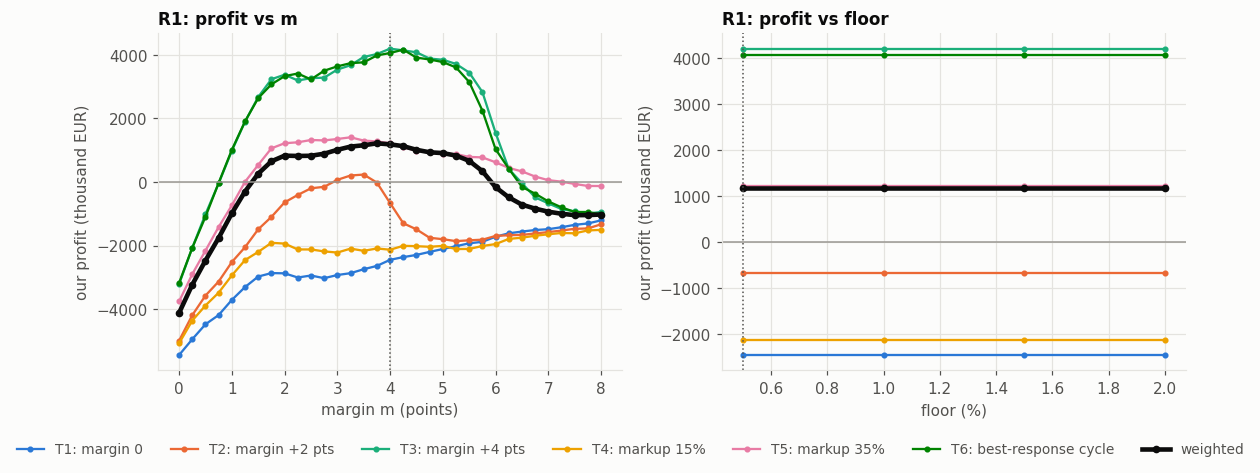

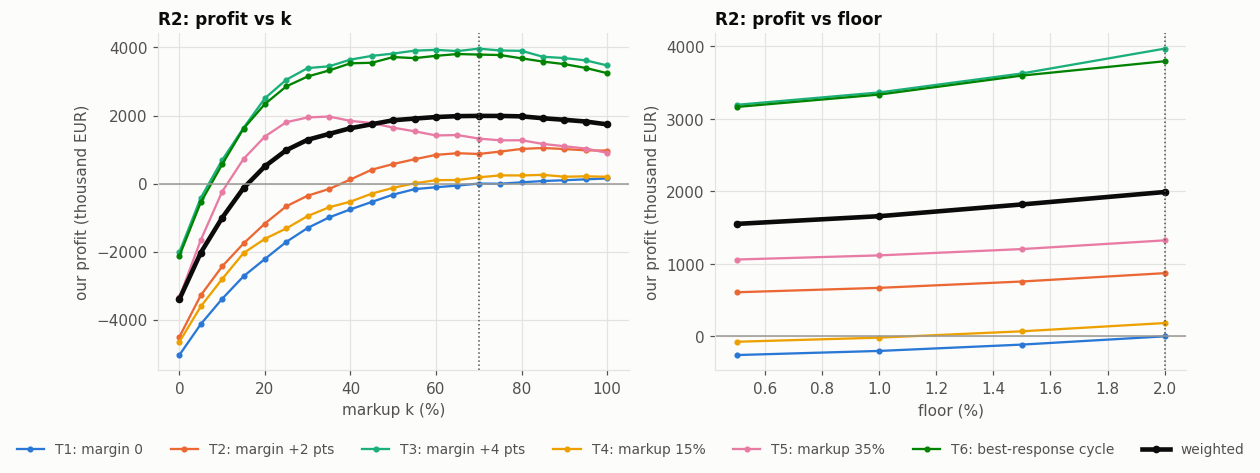

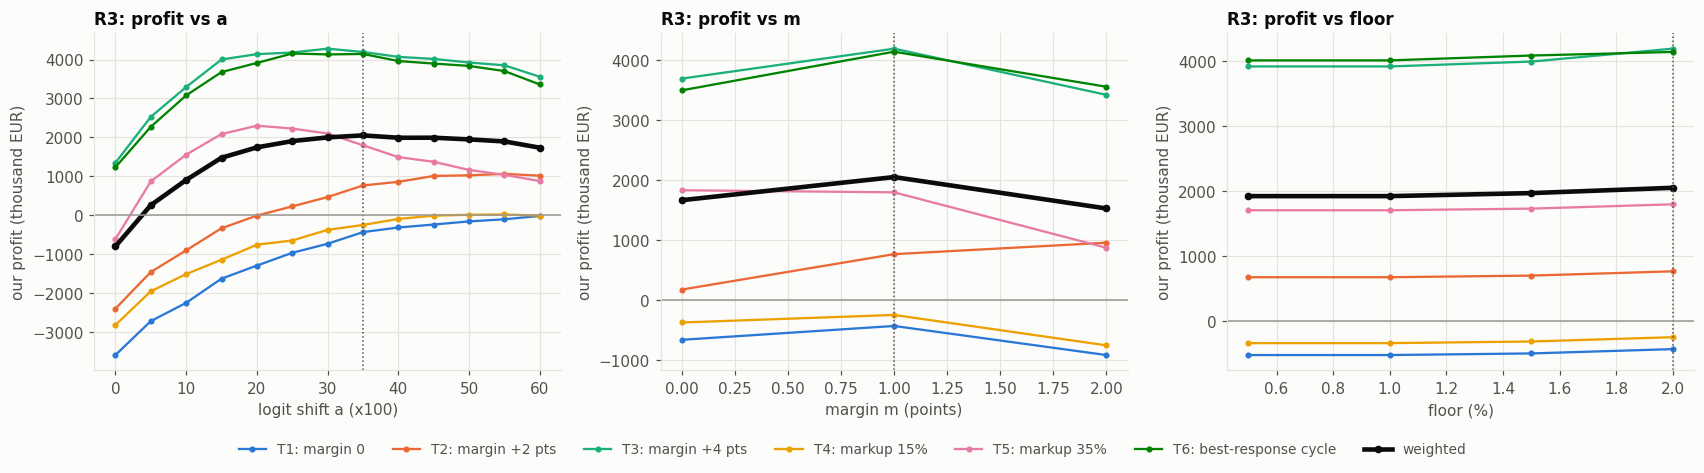

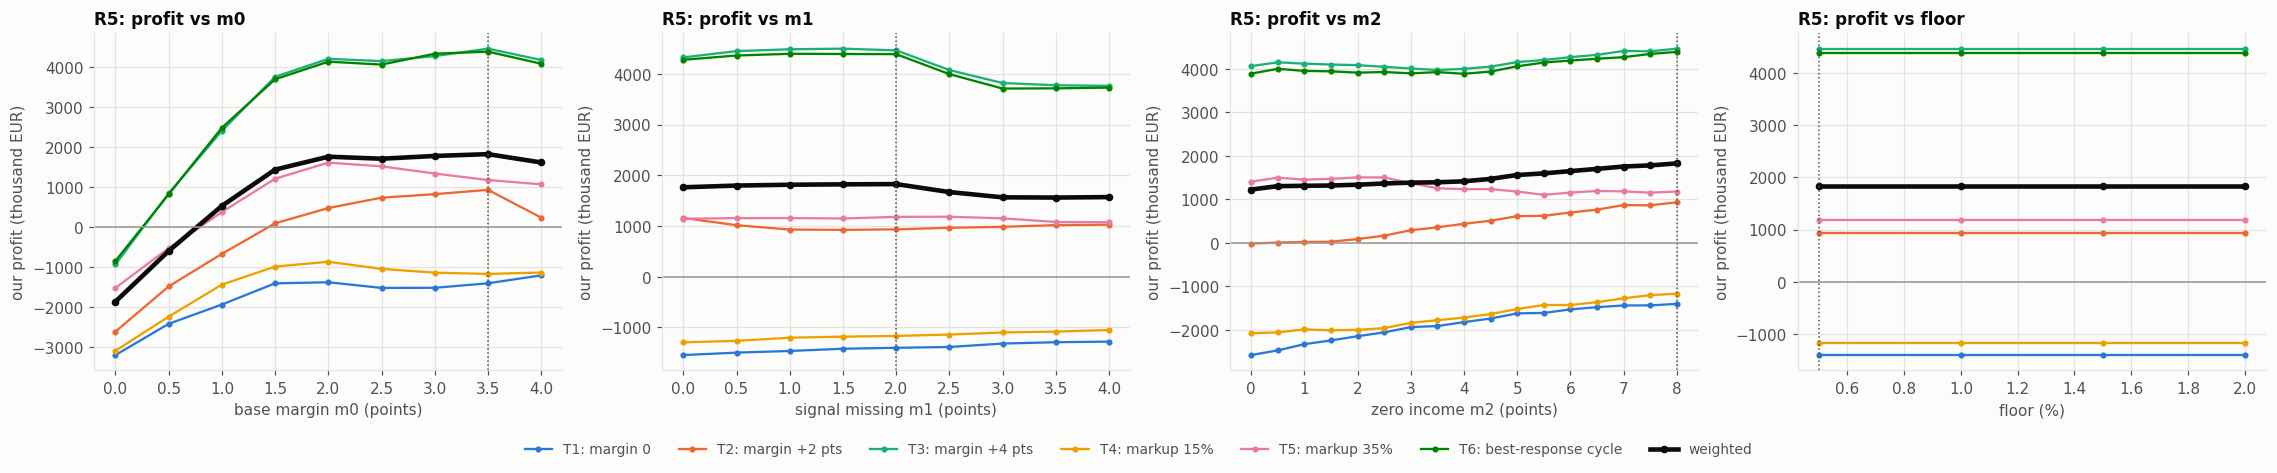

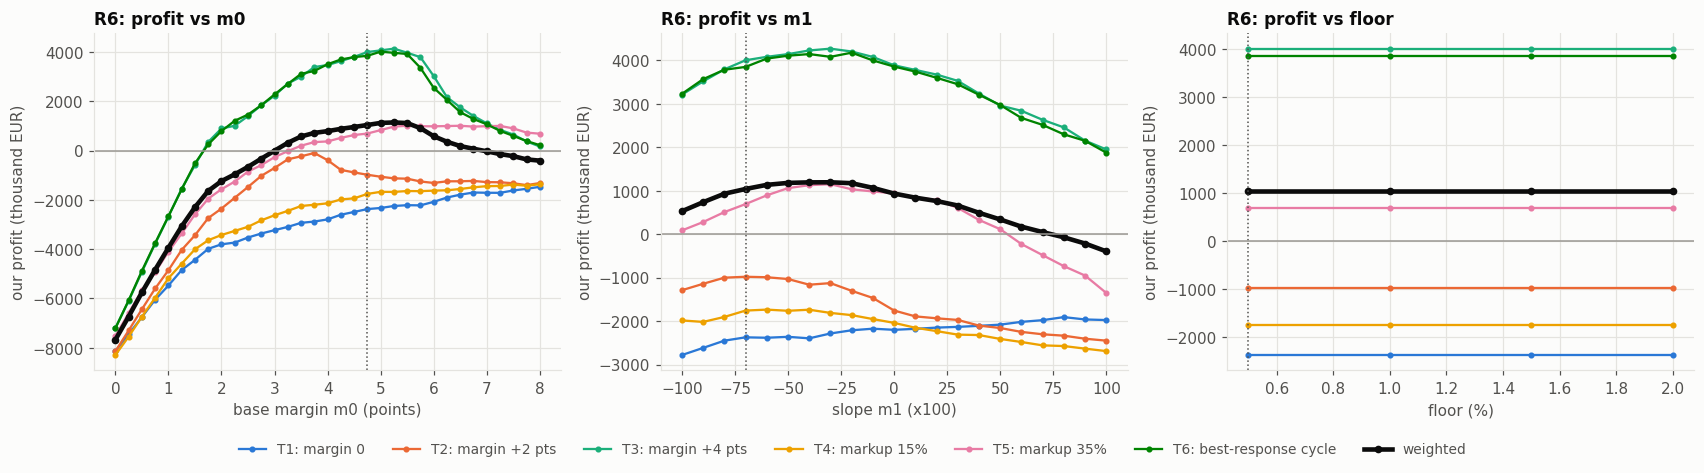

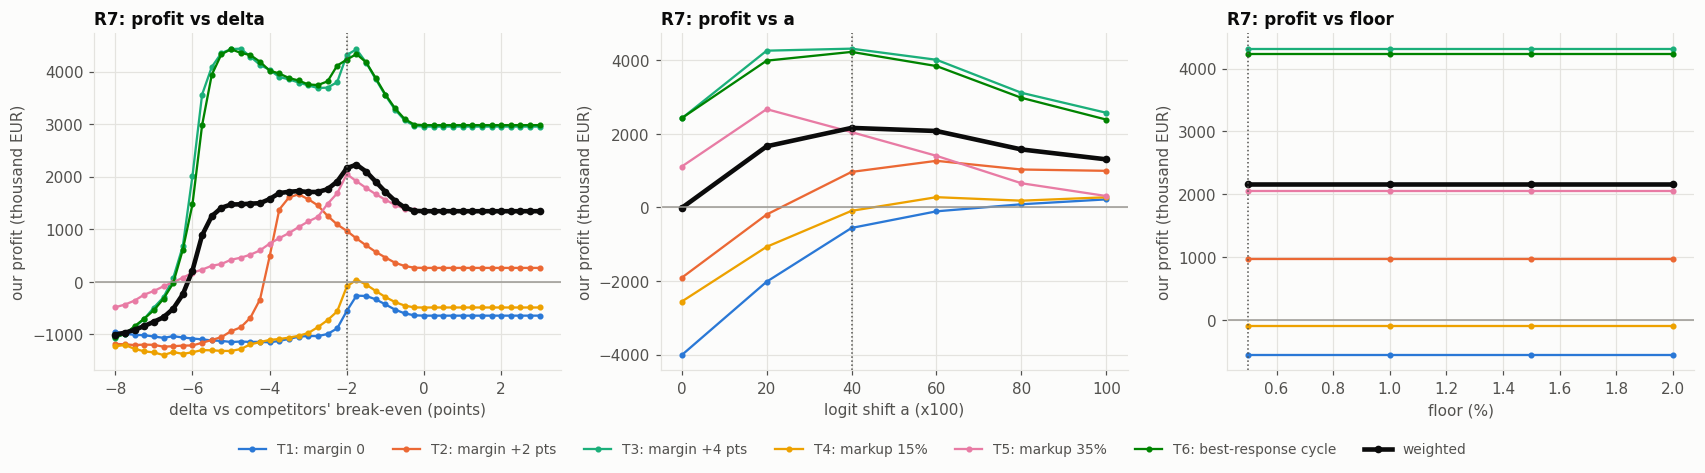

In [15]:
CURVES = {"R1": [("m", "margin m (points)")],
          "R2": [("k", "markup k (%)")],
          "R3": [("a", "logit shift a (x100)"), ("m", "margin m (points)")],
          "R5": [("m0", "base margin m0 (points)"), ("m1", "signal missing m1 (points)"),
                 ("m2", "zero income m2 (points)")],
          "R6": [("m0", "base margin m0 (points)"), ("m1", "slope m1 (x100)")],
          "R7": [("delta", "delta vs competitors' break-even (points)"),
                 ("a", "logit shift a (x100)")]}

for family, params in CURVES.items():
    panels = params + [("floor", "floor (%)")]
    fig, axes = plt.subplots(1, len(panels), figsize=(5.2 * len(panels), 4), squeeze=False)
    for ax, (param, label) in zip(axes[0], panels):
        pp.plot_profit_curves(RESULTS[family], param, TUNED[family], weights, ax,
                              f"{family}: profit vs {param}", xlabel=label)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncols=7, fontsize=9,
               labelcolor=mp.INK_SECONDARY, bbox_to_anchor=(0.5, -0.08))
    fig.tight_layout()
    plt.show()

**Findings.**

* **R1:** broad plateau from 2 to 5 points, peaking near 4 points. The scenarios disagree a lot: T1 and
  T4 lose money at every margin.
* **R2:** the weighted curve is flat from $k \approx 0.55$ to $0.85$, so the choice is robust. A 2%
  floor helps a little.
* **R3:** flat optimum in $a$ between 0.25 and 0.5; $m = 1$ point is the best of {0, 1, 2}.
* **R5:** $m_0$ matters up to 2 points, then is flat to 3.5; $m_1$ is flat up to 2 points, then
  falls; $m_2$ rises slowly all the way to 8 points.
* **R6:** $m_0$ peaks around 5 points; the $m_1$ curve peaks at −0.3 to −0.2, so the information term
  has the "wrong" sign and little effect.
* **R7:** bumpy in $\delta$, with a main peak at −2 and a second at −5 points in T3 and T6;
  $a = 0.4$ is a clear interior optimum.
* **Floor:** flat for R1, R5, R6 and R7, whose margins already exceed it. A 2% floor helps a little
  for B0, R2 and R3, which can price very safe borrowers close to 0%.
* **Scenarios:** T1 (competitors at break-even) and T4 (15% markup) are loss-making for most rules
  without a cutoff. T3 and T6 are where all rules make most of their money, and they pull the
  weighted optimum.

## 4. Part 6 deliverables

### 4.1 Tuned rules side by side

Each tuned rule (B0 and R1–R7, plus the cutoff versions) re-scored on T1–T6 with its chosen
parameters. **Regret** here is measured across families: in each scenario, the best tuned rule's
profit minus this rule's profit. The worst case over scenarios is `max regret`.

In [16]:
rows = {}
for family in TUNED:
    base = family.replace("+C", "")
    kwargs = tuned_kwargs(base)
    if family.endswith("+C"):
        kwargs["cutoff"] = TUNED[family]["cutoff"]
    floor = kwargs.pop("floor")
    rows[family] = grid_search(RULES[base], {"floor": [floor]}, scenarios, weights, train,
                               fixed=kwargs, progress=False).iloc[0]
comparison = pd.DataFrame(rows).T
profit_cols = [f"profit_{s}" for s in scenarios]
comparison["max regret"] = (comparison[profit_cols].max() - comparison[profit_cols]).max(axis=1)
comparison = comparison.sort_values("weighted", ascending=False)
display(comparison[["weighted", "max regret"] + profit_cols + ["mean_rate", "offer_share"]]
        .style.format({**{c: "{:+,.0f}" for c in ["weighted", "max regret"] + profit_cols},
                       "mean_rate": "{:.2%}", "offer_share": "{:.1%}"}))

print("Tuned parameters:")
for family, params in TUNED.items():
    shown = {k: (np.round(v, 4).tolist() if isinstance(v, np.ndarray) else round(float(v), 4))
             for k, v in params.items() if k != "edges"}
    print(f"  {family:<6} {shown}")
print(f"T6 competitor margins: lender 1 {EQ_MARGINS[0]:.2%}, lender 2 {EQ_MARGINS[1]:.2%} "
      f"({'equilibrium' if eq['converged'] else 'average over the best-response cycle'})")

,weighted,max regret,profit_T1,profit_T2,profit_T3,profit_T4,profit_T5,profit_T6,mean_rate,offer_share
R4+C,"+2,965,014","+97,975","+437,211","+1,893,452","+5,198,170","+965,889","+2,054,658","+5,102,861",9.70%,65.8%
R7+C,"+2,941,165","+120,916","+340,517","+1,991,427","+5,119,597","+1,047,133","+2,125,591","+4,981,944",7.48%,55.6%
R4,"+2,706,980","+394,063","+143,644","+1,597,364","+4,901,661","+665,266","+1,973,492","+4,833,716",20.66%,100.0%
R7,"+2,163,506","+1,138,198","-556,427","+966,974","+4,317,866","-91,065","+2,048,061","+4,229,567",17.91%,99.8%
R3,"+2,051,672","+1,296,711","-433,295","+764,993","+4,194,578","-249,578","+1,797,070","+4,143,967",17.84%,99.8%
R2,"+1,988,901","+1,310,948","-1,027","+869,922","+3,965,353","+182,114","+1,322,123","+3,791,913",20.00%,99.5%
R5,"+1,825,763","+2,213,674","-1,400,689","+933,685","+4,460,970","-1,166,541","+1,179,648","+4,386,635",17.25%,100.0%
R1,"+1,184,443","+3,179,830","-2,451,189","-664,622","+4,197,710","-2,132,697","+1,219,779","+4,061,059",15.97%,100.0%
R6,"+1,039,777","+2,971,332","-2,373,387","-979,905","+4,001,056","-1,757,947","+692,310","+3,848,155",16.68%,100.0%
B0,"-3,402,836","+7,229,678","-5,041,648","-4,507,598","-2,017,701","-4,653,687","-3,345,585","-2,126,817",12.13%,100.0%


Tuned parameters:
  B0     {'floor': 0.02}
  R1     {'m': 0.04, 'floor': 0.005}
  R2     {'k': 0.7, 'floor': 0.02}
  R3     {'a': 0.35, 'm': 0.01, 'floor': 0.02}
  R4     {'floor': 0.005, 'centres': [0.0053, 0.0197, 0.0358, 0.0542, 0.0753, 0.0986, 0.1232, 0.1409, 0.1774, 0.2508], 'margins': [0.0175, 0.0175, 0.02, 0.0317, 0.0317, 0.0317, 0.1688, 0.1688, 0.1938, 0.1938]}
  R5     {'m0': 0.035, 'm1': 0.02, 'm2': 0.08, 'floor': 0.005}
  R6     {'m0': 0.0475, 'm1': -0.7, 'floor': 0.005}
  R7     {'delta': -0.02, 'q': 0.5, 'a': 0.4, 'floor': 0.005}
  R4+C   {'floor': 0.005, 'centres': [0.0053, 0.0197, 0.0358, 0.0542, 0.0753, 0.0986, 0.1232, 0.1409, 0.1774, 0.2508], 'margins': [0.0175, 0.0175, 0.02, 0.0317, 0.0317, 0.0317, 0.1688, 0.1688, 0.1938, 0.1938], 'cutoff': 0.125}
  R7+C   {'delta': -0.02, 'q': 0.5, 'a': 0.4, 'floor': 0.005, 'cutoff': 0.1}
T6 competitor margins: lender 1 4.25%, lender 2 3.75% (average over the best-response cycle)


* **R4+C is first on both criteria**: the highest weighted profit (+€2.97M) and the smallest max
  regret across rules (€0.10M). It is **profitable in all six scenarios**, including T1 (+€0.44M) and
  T4 (+€0.97M), where most rules lose money.
* **R7+C is a very close second** (+€2.94M, max regret €0.12M) and also profitable in all six
  scenarios. The two rules differ by €24k, under 1% of profit.
* R4 without a cutoff (+€2.71M) is the only other rule that is profitable in every scenario. Every
  other rule loses money in T1, and R7, R3, R5, R1 and R6 also in T4.
* All tuned rules beat B0 by €4.4M to €6.4M of weighted profit. With cutoffs, we make offers to only
  56–66% of applicants.

### 4.2 Winner's curse of the tuned rules

In scenario T6 (the best-response cycle), the gap between the observed default rate and our predicted
probability on the loans we win, by quintile of `p_own` (G1 = safest). A positive gap means we
under-estimate the risk of the borrowers we win. A good rule either keeps the gap small or charges
enough to cover it.

In [17]:
curse_rows, outcome_rows = {}, {}
for family in comparison.index:
    base = family.replace("+C", "")
    kwargs = tuned_kwargs(base)
    if family.endswith("+C"):
        kwargs["cutoff"] = TUNED[family]["cutoff"]
    row, curse = evaluate(RULES[base], kwargs, scenarios["T6"], train, scenario_name="T6")
    outcome_rows[family] = row
    curse_rows[family] = curse["gap"]

print("Outcome in T6 (best-response cycle):")
display(pd.DataFrame(outcome_rows).T.style.format(
    {"profit": "{:+,.0f}", "n_loans": "{:,.0f}", "share": "{:.1%}", "avg_rate": "{:.2%}",
     "default_rate_won": "{:.2%}", "gap": "{:+.2%}"}))
print("Winner's-curse gap (observed - predicted) by quintile of p_own, T6:")
display(pd.DataFrame(curse_rows).T.style.format("{:+.2%}", na_rep="no loans"))

Outcome in T6 (best-response cycle):


,profit,n_loans,share,avg_rate,default_rate_won,gap
R4+C,"+5,102,861","29,733",37.2%,6.56%,4.40%,+0.51%
R7+C,"+4,981,944","26,484",33.1%,6.26%,4.02%,+0.46%
R4,"+4,833,716","30,011",37.5%,6.86%,4.68%,+0.67%
R7,"+4,229,567","30,110",37.6%,8.34%,5.99%,+1.24%
R3,"+4,143,967","29,587",37.0%,8.24%,5.87%,+1.28%
R2,"+3,791,913","25,949",32.4%,6.58%,4.45%,+1.00%
R5,"+4,386,635","23,839",29.8%,12.13%,8.73%,+1.61%
R1,"+4,061,059","26,867",33.6%,13.60%,10.15%,+1.78%
R6,"+3,848,155","27,862",34.8%,13.39%,10.16%,+1.41%
B0,"-2,126,817","61,737",77.2%,8.94%,8.11%,+0.44%


Winner's-curse gap (observed - predicted) by quintile of p_own, T6:


,G1,G2,G3,G4,G5,overall
R4+C,+0.15%,+0.28%,+1.36%,+16.50%,no loans,+0.51%
R7+C,+0.19%,+0.26%,+1.69%,no loans,no loans,+0.46%
R4,+0.15%,+0.28%,+1.36%,+16.91%,+17.89%,+0.67%
R7,+0.19%,+0.26%,+1.73%,+7.89%,+9.88%,+1.24%
R3,+0.16%,+0.35%,+1.91%,+7.75%,+8.99%,+1.28%
R2,+0.12%,+0.36%,+2.94%,+10.93%,+13.77%,+1.00%
R5,+0.22%,+0.47%,+1.29%,+4.01%,+7.03%,+1.61%
R1,+0.17%,+0.47%,+1.47%,+3.43%,+5.07%,+1.78%
R6,+0.19%,+0.53%,+1.07%,+2.26%,+4.00%,+1.41%
B0,+0.08%,-0.01%,+0.18%,+0.75%,+2.72%,+0.44%


* **The two best rules lend to a safer third of the market in T6.**
  * **R4+C:** 37% of applicants, average rate 6.6%, default rate 4.4%, gap +0.5 point, profit +€5.10M.
  * **R7+C:** 33% of applicants, 6.3%, 4.0%, gap +0.5 point, +€4.98M.
* **B0 wins 77% of applicants at break-even and loses €2.13M**, even though its gap is small (+0.4
  point). With zero margin, any gap loses money. And because B0 wins almost everyone, there is little
  selection to cause a gap.
* **The winner's curse lives in the risky quintiles.** Without a cutoff, the borrowers R4 still wins in
  G4–G5 (at margins of 17–19 points) default 17–18 points above our prediction. They take our offer
  precisely because the competitors, who know more, charged them even more. Other rules show
  +2 to +14 points in G4–G5.
* **The cutoffs remove those quintiles altogether** ("no loans": R4+C lends nothing in G5, R7+C nothing
  in G4–G5). That is why their overall gap falls to about +0.5 point. In G1–G3 the gap stays small
  (+0.1 to +1.7 points) for every rule.

### 4.3 Saving the tuned rules

Saved to `data/pricing/tuned_rules.json` (with the equilibrium margins), for Part 7, which scores
these rules on the validation set against held-out scenarios, and Part 8.

In [ ]:
to_save = {family: dict(params) for family, params in TUNED.items()}
to_save["equilibrium"] = {"converged": eq["converged"], "rounds": eq["rounds"],
                          "last_round": list(eq["margins"]), "cycle_mean": list(eq["cycle_mean"]),
                          "T6_margins": list(EQ_MARGINS)}
path = save_tuned(to_save, filename=f"tuned_rules{TAG}.json")
print(f"saved {path}")

`tuned_rules.json` holds the chosen parameters of every family. R4 is stored as its decile edges, the
decile centres and the smoothed margins at those centres, which is enough to rebuild the curve with
`smooth_bin_margins`. The `equilibrium` entry records that the best responses did not converge
(20 rounds), the last round, the cycle averages, and the margins used for T6 (4.25% and 3.75%).

## 5. Summary and conclusion

### What we did

Eight families of pricing rules (B0, R1–R7), plus a no-offer cutoff, were tuned on the 80,000
training loans. Each one was simulated against six competitor scenarios:

* break-even plus 0, 2 or 4 points;
* a 15% or 35% markup on break-even;
* the average margins of best-responding competitors (T6).

Parameters were chosen on the scenario-weighted profit, with max regret as a second criterion, and the
rate floor was tuned in every family. Two corrections were made along the way:

### Results

| rank | rule | parameters | weighted profit | max regret (across rules) | T1 profit | T6 profit | T6 share |
|---|---|---|---|---|---|---|---|
| 1 | **R4+C** margin per decile + cutoff | 1.75–2 pts (p < 4.5%), 3.2 pts (4.5–11%); no offer from p = 0.125 | **+€2.97M** | **€0.10M** | +€0.44M | **+€5.10M** | 37.2% |
| 2 | **R7+C** competitor-based + cutoff | 2 pts above competitors' predicted break-even, a = 0.4; no offer from p = 0.10 | +€2.94M | €0.12M | +€0.34M | +€4.98M | 33.1% |
| 3 | R4 | as R4+C, no cutoff (prices p > 11% out) | +€2.71M | €0.39M | +€0.14M | +€4.83M | 37.5% |
| 4 | R7 | as R7+C, no cutoff | +€2.16M | €1.14M | −€0.56M | +€4.23M | 37.6% |
| 5 | R3 adjusted p | a = 0.35, m = 1 pt, floor 2% | +€2.05M | €1.30M | −€0.43M | +€4.14M | 37.0% |
| 6 | R2 markup | k = 0.70, floor 2% | +€1.99M | €1.31M | −€0.00M | +€3.79M | 32.4% |
| 7 | R5 uncertainty | m0 = 3.5, m1 = 2, m2 = 8 pts | +€1.83M | €2.21M | −€1.40M | +€4.39M | 29.8% |
| 8 | R1 fixed margin | m = 4 pts | +€1.18M | €3.18M | −€2.45M | +€4.06M | 33.6% |
| 9 | R6 info advantage | m0 = 4.75 pts, m1 = −0.7 | +€1.04M | €2.97M | −€2.37M | +€3.85M | 34.8% |
| 10 | B0 break-even | floor 2% | −€3.40M | €7.23M | −€5.04M | −€2.13M | 77.2% |

Profits are on the 80,000 training loans; the real round has 100,000 applicants (about ×1.25).

### What we learned

1. **Break-even pricing loses money in every scenario** (−€3.4M weighted). Every tuned rule adds a
   margin and turns this into a profit of €1.0M to €3.0M.
2. **Profit depends heavily on the competitors** (3a: from −€0.4M to +€7.9M for the same rule), and
   **there is no stable equilibrium**: best-responding lenders cycle between about 2.25 and 5.25 points
   (an Edgeworth cycle), averaging 3–4.5 points over break-even.
3. **The margin must grow with risk.** Rules whose margin rises with $p$ (R2, R3, R4) beat a flat
   margin (R1) by €0.8M to €1.5M. R4 shows the shape directly: about 2 points for $p$ below 4.5%,
   about 3 points between 4.5% and 11%, and no lending above that.
4. **Do not lend to the riskiest borrowers.** Above $p_{own} \approx 11$–12%, lending does not pay at
   any margin: the borrowers we would win there default 8–18 points above our prediction. A cutoff at
   0.10–0.125 adds €0.26M (R4) and €0.78M (R7), and **makes both rules profitable in all six
   scenarios**. We then lend to only 56–66% of applicants.
5. **Removing R7's information leak cost €0.65M** (+€2.81M → +€2.16M before the cutoff). Without the
   leak, the competitor-based rule is only competitive once it has a cutoff.
6. **Uncertainty flags and information-advantage pricing add little.** Zero-income applicants are best
   priced out (+8 points), a missing signal is worth only about 2 points, and charging more where our
   signal is more optimistic than the public data (R6) does not help.
7. **The rate floor is a detail**: irrelevant for rules with a margin of 2 points or more, slightly
   useful (2%) for rules that can price safe borrowers near 0%.
8. **The winner's curse is concentrated in the risky quintiles.** The best rules do not correct our
   probabilities there; they **stop lending** there and keep a margin of 2–3 points where the gap is
   small (+0.1 to +1.7 points).

### Conclusion

**R4+C is our recommended rule**:

* the highest weighted profit and the smallest regret;
* profitable in all six scenarios;
* simple and transparent: it uses only `p_own`, with a margin of about 2–3 points over break-even
  and no offer above $p = 0.125$;
* directly applicable to the new applicants.

**R7+C is statistically indistinguishable** (€24k, under 1% of profit) and reaches the same policy by
another route: lend only to the safer half of the market, about 2 points above the competitors'
predicted break-even. It needs more machinery (the competitor model and `p_public` for the
applicants), so we keep it as the challenger.

**Rules carried to Part 7:** R4+C and R7+C, plus R3 (the best simple parametric rule), R2 (the most
robust without a cutoff when competitors are aggressive), and B0 and R1 as references. Part 7 scores
them on the validation set against held-out scenarios (asymmetric margins, +1/+3/+5 points,
competitors using our rule, competitors knowing more or less). Its results, not these training-set
profits, decide the submission.

### Limitations

* **Profits are in-sample.** The rules were tuned and scored on the same 80,000 loans, so these
  figures are optimistic; Part 7's validation scores are the ones to trust.
* **The scenario weights (T6 = 2/7) are a judgement call**, and T6 is a cycle average rather than an
  equilibrium.
* **R7+C's best cutoff (0.10) is the lowest value tried.** R5's $m_2$ and R4's top-decile margins are
  also at the edge of their grids, but there the edge only means "price these borrowers out", the same
  as a cutoff.
* **The selection rule's tie-break** ("keep the higher margin" when the criteria disagree) cost
  €30–200k of weighted profit in R1, R6 and R7. That is small, and it was chosen deliberately as the
  cautious option.